In [1]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import squidpy as sq
import anndata as ad
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
in_dir = "../../results/04_spatial_clustering/01_run_cellcharter"
out_dir = "../../results/04_spatial_clustering/05_find_markers"
os.makedirs(out_dir, exist_ok=True)

In [3]:
adata = sc.read_h5ad(f"{in_dir}/adata_cellcharter_merged.h5ad")

In [4]:
adata

AnnData object with n_obs × n_vars = 19740 × 1410
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', '_indices', '_scvi_batch', '_scvi_labels', 'ATL', 'CNT', 'DCT', 'DTL', 'EC', 'FIB', 'IC', 'IMM_B', 'IMM_MAC_M2', 'IMM_MAST', 'IMM_MDC', 'IMM_N', 'IMM_NKT', 'IMM_PL', 'IMM_T', 'IMM_cDC', 'IMM_cycMNP', 'IMM_ncMON', 'IMM_pDC', 'NEU', 'PC', 'PEC', 'POD', 'PT', 'PapE', 'TAL', 'VSM_P', 'cluster_cellcharter'
    var: 'gene_ids', 'feature_types', 'genome', 'MT_gene'
    obsm: 'MT', 'X_cell2location', 'X_cellcharter', 'means_cell_abundance_w_sf', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [5]:
adata.layers['counts'] = adata.X.copy()

In [6]:
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.log1p(adata)

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [7]:
sc.tl.rank_genes_groups(adata, groupby="cluster_cellcharter", method="wilcoxon")

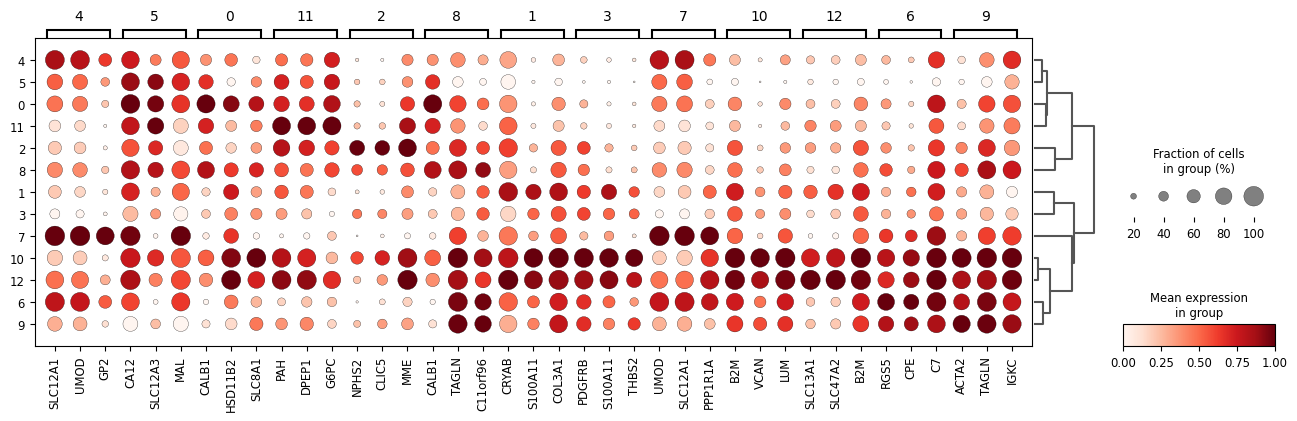

In [8]:
sc.pl.rank_genes_groups_dotplot(adata, 
                                groupby="cluster_cellcharter", 
                                standard_scale="var", n_genes=3,
                                save="_cellcharter_clusters_dotplot.pdf", figsize=(16, 4))

In [9]:
df_markers = sc.get.rank_genes_groups_df(adata, group=None).groupby("group").head(100).reset_index(drop=True)

In [10]:
df_markers

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CALB1,48.142822,6.635135,0.000000e+00,0.000000e+00
1,0,HSD11B2,31.800579,3.214243,6.354660e-222,4.480035e-219
2,0,SLC8A1,30.767570,3.769872,7.118317e-208,3.345609e-205
3,0,CA12,30.340940,1.447430,3.308528e-202,1.166256e-199
4,0,SLC12A3,30.130358,4.450290,1.940151e-199,5.471227e-197
...,...,...,...,...,...,...
1295,12,CLDN1,27.140930,5.397458,3.239997e-162,4.758746e-161
1296,12,APBB1IP,27.106705,5.279538,8.208192e-162,1.193150e-160
1297,12,FGD5,27.058743,5.166847,3.013970e-161,4.336426e-160
1298,12,DOCK11,26.978237,5.333476,2.661204e-160,3.790199e-159


In [12]:
df_markers.to_csv(f"{out_dir}/marker_genes_cellcharter_clusters.csv", index=False)